In [1]:
try:
    import google.colab
    print('Running on CoLab')
    #!pip install roboticstoolbox-python>=1.0.2
    !pip install git+https://github.com/petercorke/robotics-toolbox-python@future
    !pip install spatialmath-python>=1.1.5
    !pip install bdsim
    !pip install --no-deps rvc3python
    COLAB = True
except ModuleNotFoundError:
    COLAB = False

from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "last_expr_or_assign"

In [28]:
from IPython.display import HTML

import matplotlib.pyplot as plt

# add RTB examples folder to the path
import sys, os.path
import RVC3 as rvc
models_dir = os.path.join(rvc.__path__[0], 'models')
sys.path.append(models_dir)

# ------ standard imports ------ #
import numpy as np
import math
from math import pi
np.set_printoptions(
    linewidth=120, formatter={
        'float': lambda x: f"{0:8.4g}" if abs(x) < 1e-10 else f"{x:8.4g}"})
np.random.seed(0)
from spatialmath import *
from spatialmath.base import *
from roboticstoolbox import *

%matplotlib widget

### Distance Transform

In [3]:
simplegrid = np.zeros((6, 6))
simplegrid[2:5, 3:5] = 1
simplegrid[3:5, 2] = 1

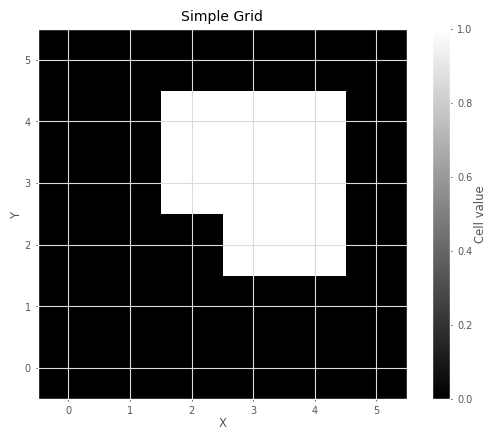

In [6]:
plt.imshow(simplegrid, cmap="gray", origin="lower")
plt.colorbar(label="Cell value")
plt.xlabel("X")
plt.ylabel("Y")
plt.title("Simple Grid")
plt.xticks(range(6))
plt.yticks(range(6))
plt.grid(True)
plt.show()

In [4]:
dx = DistanceTransformPlanner(occgrid=simplegrid)

DistanceTransformPlanner: 
  BinaryOccupancyGrid: 6 x 6, cell size=1, x = [0.0, 5.0], y = [0.0, 5.0], 22.2% occupied
  Distance metric: euclidean, Distance map: empty 

In [7]:
dx.plan(goal=(1, 1))

<Axes: xlabel='x', ylabel='y'>

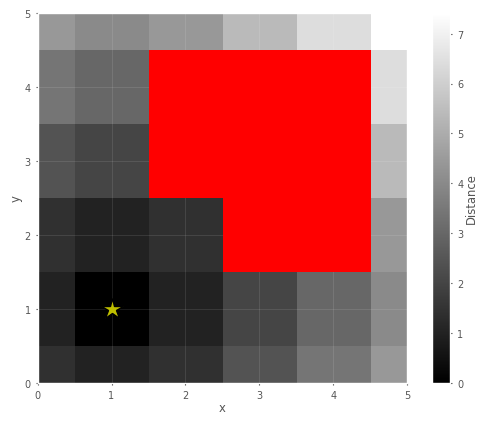

In [8]:
dx.plot(labelvalues=True)

<Axes: xlabel='x', ylabel='y'>

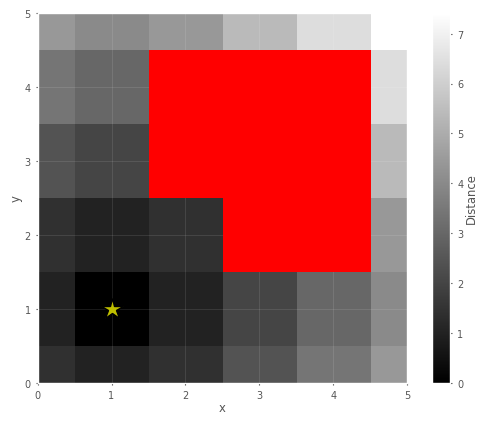

In [9]:
dx = DistanceTransformPlanner(occgrid=simplegrid, distance="manhattan")
dx.plan(goal=(1, 1))
dx.plot(labelvalues=True)

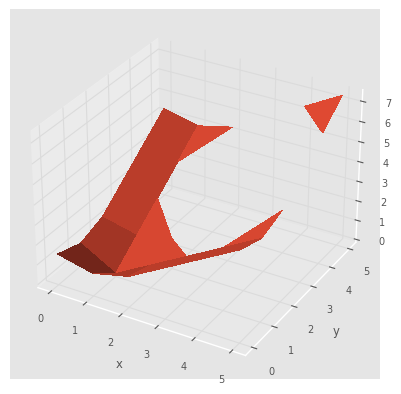

<Axes3D: xlabel='x', ylabel='y', zlabel='z'>

In [10]:
dx.plot_3d()

In [11]:
path = dx.query(start=(5, 4))

array([[5, 4],
       [5, 3],
       [5, 2],
       [4, 1],
       [3, 1],
       [2, 1],
       [1, 1]])

<Axes: xlabel='x', ylabel='y'>

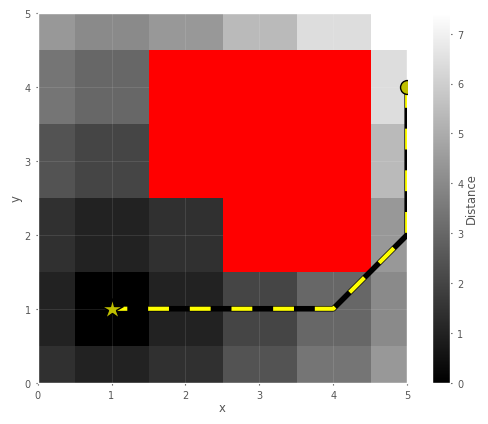

In [12]:
dx.plot(path)

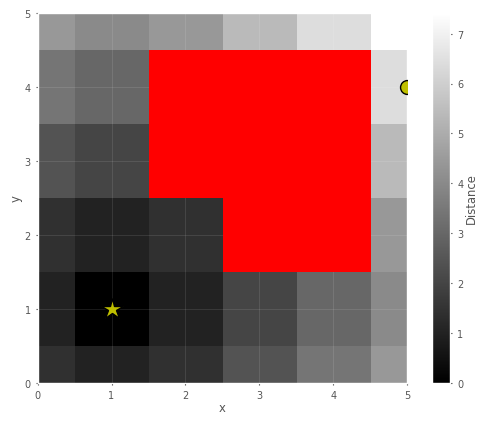

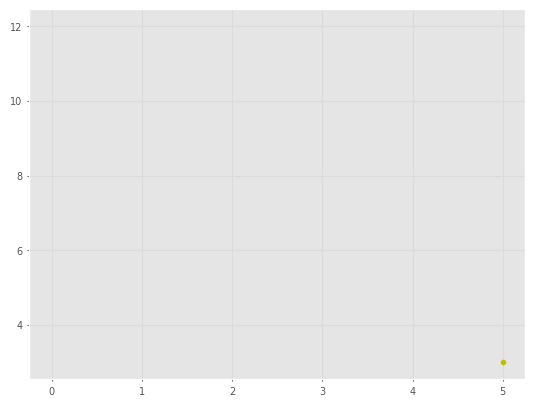

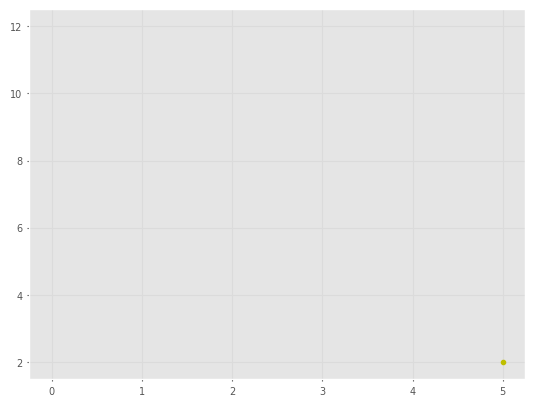

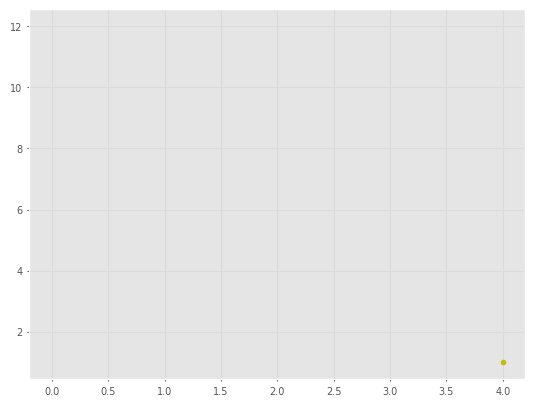

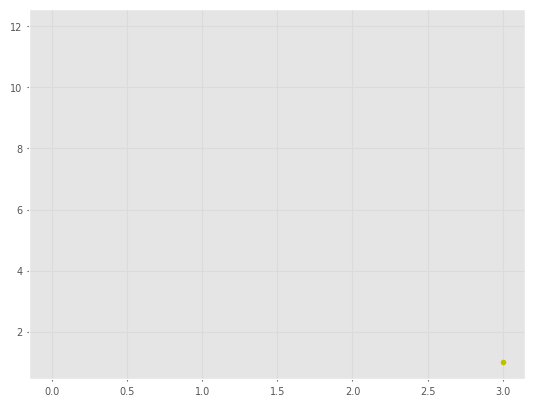

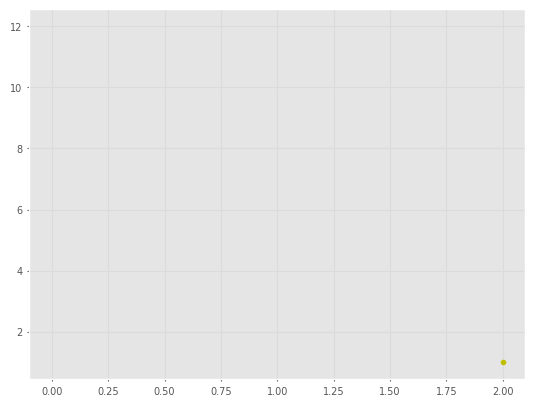

array([[5, 4],
       [5, 3],
       [5, 2],
       [4, 1],
       [3, 1],
       [2, 1],
       [1, 1]])

In [13]:
dx.query(start=(5, 4), animate=True)

In [23]:
house = rtb_load_matfile("data/house.mat")
floorplan = house["floorplan"]
places = house["places"]

{'kitchen': array([320, 190], dtype=uint16),
 'garage': array([500, 150], dtype=uint16),
 'br1': array([ 50, 220], dtype=uint8),
 'br2': array([120,  50], dtype=uint8),
 'br3': array([50, 50], dtype=uint8),
 'nook': array([320, 280], dtype=uint16),
 'mudroom': array([320,  50], dtype=uint16),
 'patio': array([200, 350], dtype=uint16),
 'study': array([220,  50], dtype=uint8),
 'garden': array([100, 350], dtype=uint16),
 'driveway': array([500, 350], dtype=uint16),
 'living': array([220, 200], dtype=uint8)}

<Axes: xlabel='x', ylabel='y'>

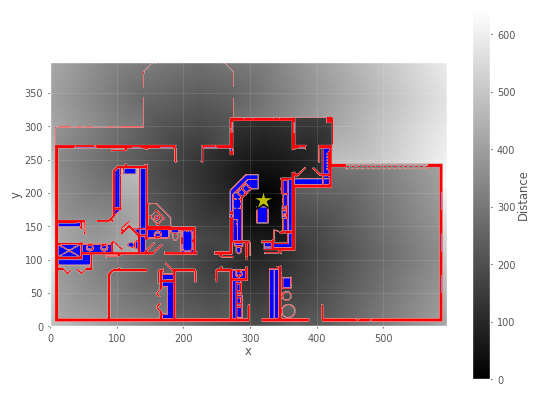

In [24]:
dx = DistanceTransformPlanner(occgrid=floorplan)
dx.plan(goal=places.kitchen)
dx.plot()

In [25]:
path = dx.query(start=places.br3)
path.shape

(338, 2)

<Axes: xlabel='x', ylabel='y'>

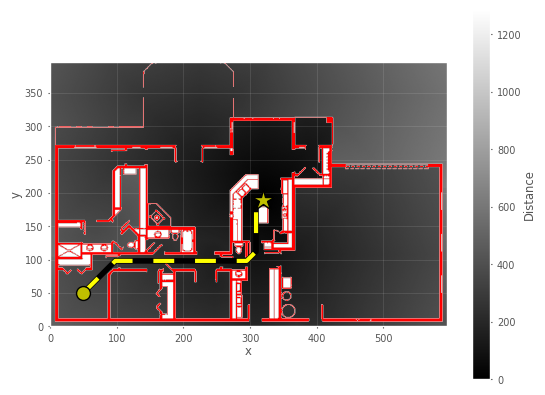

In [26]:
dx.plot(path)

In [27]:
dx.plan(places.kitchen, summary=True)

571 iterations, 9925 unreachable cells


In [30]:
# dx.plan(places.kitchen, animate=True)

In [31]:
dx = DistanceTransformPlanner(occgrid=floorplan, inflat=5)
dx.plan(places.kitchen)
p = dx.query(places.br3)
dx.plot(p)

<Axes: xlabel='x', ylabel='y'>

### D*

In [32]:
dstar = DstarPlanner(occgrid=floorplan)

DstarPlanner: 
  BinaryOccupancyGrid: 596 x 397, cell size=1, x = [0.0, 595.0], y = [0.0, 396.0], 8.8% occupied

In [33]:
c = dstar.costmap

array([[       1,        1,        1, ...,        1,        1,        1],
       [       1,        1,        1, ...,        1,        1,        1],
       [       1,        1,        1, ...,        1,        1,        1],
       ...,
       [       1,        1,        1, ...,        1,        1,        1],
       [       1,        1,        1, ...,        1,        1,        1],
       [       1,        1,        1, ...,        1,        1,        1]], shape=(397, 596))

In [34]:
dstar.plan(goal=places.kitchen)

In [35]:
nexpand0 = dstar.nexpand

359764

In [36]:
path = dstar.query(start=places.br3)

(array([[ 50,  50],
        [ 51,  50],
        [ 52,  50],
        [ 53,  50],
        [ 54,  50],
        [ 55,  50],
        [ 56,  50],
        [ 57,  51],
        [ 58,  52],
        [ 59,  53],
        [ 60,  54],
        [ 61,  55],
        [ 62,  55],
        [ 63,  56],
        [ 64,  56],
        [ 65,  57],
        [ 66,  58],
        [ 67,  59],
        [ 68,  60],
        [ 69,  61],
        [ 70,  62],
        [ 71,  63],
        [ 72,  64],
        [ 73,  65],
        [ 74,  66],
        [ 75,  67],
        [ 76,  68],
        [ 77,  69],
        [ 78,  70],
        [ 79,  71],
        [ 80,  72],
        [ 81,  73],
        [ 82,  74],
        [ 83,  75],
        [ 84,  76],
        [ 85,  77],
        [ 86,  78],
        [ 87,  79],
        [ 88,  80],
        [ 89,  81],
        [ 90,  82],
        [ 91,  83],
        [ 92,  84],
        [ 93,  85],
        [ 94,  86],
        [ 95,  87],
        [ 96,  88],
        [ 97,  89],
        [ 98,  90],
        [ 99,  91],


In [37]:
def sensorfunc(pos):
    if pos[0] == 300: # near the door?
        changes = []
        for x in range(300, 325):
            for y in range(115, 125):
                changes.append((x, y, np.inf))
        return changes

In [39]:
dstar.query(start=places.br3, sensor=sensorfunc)

propagate
propagate


(array([[ 50,  50],
        [ 51,  50],
        [ 52,  50],
        [ 53,  50],
        [ 54,  50],
        [ 55,  50],
        [ 56,  50],
        [ 57,  51],
        [ 58,  52],
        [ 59,  53],
        [ 60,  54],
        [ 61,  55],
        [ 62,  55],
        [ 63,  56],
        [ 64,  56],
        [ 65,  57],
        [ 66,  58],
        [ 67,  59],
        [ 68,  60],
        [ 69,  61],
        [ 70,  62],
        [ 71,  63],
        [ 72,  64],
        [ 73,  65],
        [ 74,  66],
        [ 75,  67],
        [ 76,  68],
        [ 77,  69],
        [ 78,  70],
        [ 79,  71],
        [ 80,  72],
        [ 81,  73],
        [ 82,  74],
        [ 83,  75],
        [ 84,  76],
        [ 85,  77],
        [ 86,  78],
        [ 87,  79],
        [ 88,  80],
        [ 89,  81],
        [ 90,  82],
        [ 91,  83],
        [ 92,  84],
        [ 93,  85],
        [ 94,  86],
        [ 95,  87],
        [ 96,  88],
        [ 97,  89],
        [ 98,  90],
        [ 99,  91],


In [40]:
dstar.nexpand - nexpand0

42792